- Github repository: https://github.com/Simen03/simen03-ind320-app 
- Streamlit app: https://simen03-ind320-app-hkg3slagiyz8dtmwljxdtd.streamlit.app/
- Link to video: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=341f3e25-d0d5-4c22-b7bc-b4e9012f4831

### AI usage

I used AI pretty much as in the first assignment.

During the assignment I used Claude to help me break down the task to smaller tasks and to describe what I needed to do in some of the casses that I didn't understand how to solve on my own

I used the github copilot in VS code if I had some trouble with the code or something didn't work. I also used it to import the different libaries i needed. 

### Log

In this assignment I extended the reservoir project from part 1 with live data from two APIs and a database pipeline, and I updated the Streamlit app to use it. I started in the Jupyter Notebook by replacing the CSV file with a connection to the NVE Magasinstatistikk API. I put the download, column renaming and date conversion in a separate module, so that the notebook and the Streamlit app use the same code. I then recreated the plots from part 1 for Norway, with each column plotted separately and all columns together scaled to a range from 0 to 1.

The second part was getting the cross-border flow data into a database. I used the ENTSO-E API through the entsoe-py package to download the physical flows between Norway and its neighbours, in both directions, for the last two years. The API only allows one year per request, so I fetched the data in two periods and converted everything to hourly values in UTC. The data was then written to Cassandra running in Docker, using Spark, and read back with Spark to extract the columns I needed. Cassandra, Spark and the connection between them was new to me, and most of the work went into the setup. I had problems with the Hadoop winutils path on Windows, with the Java version, and with which Python environment Spark used. 

The third part was updating the Streamlit app. The slider from page three now decides which data are downloaded from the API, and radio buttons select the area type so that the table and the plots show one line for each area number. I also changed the data table so that the LineChartColumn() shows the whole selected period and not only the first month, because I thought this was better for the user. The new cross-border flow page is split into two columns with st.columns: on the left I select the connection and the year and see a pie chart of the total flow in and out of Norway, and on the right I select any set of months with st.pills and see the hourly flow as a line plot. Below the columns an expander documents the data source. I used @st.cache_data and @st.cache_resource so that the API data and the database connection are not reloaded every time the app reruns. The MongoDB connection string is stored in the Streamlit secrets, and I copied it to the settings on streamlit.io instead of putting it in the repository.

The main challenges were the setup of Spark and Cassandra and keeping the notebook and the app consistent, for example when column names changed after I moved from the CSV file to the API. Since I had never used either Spark, Cassandra or MongoDB was working with these a bit challenging for me, but a very good experience. 

### Imports

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os
import sys
from pyspark.sql import SparkSession, functions as F
from pathlib import Path
from cassandra.cluster import Cluster
from pymongo import MongoClient
import tomllib
from entsoe import EntsoePandasClient

### Importing the data

In [ ]:
sys.path.append(str(Path.cwd().parent))

# import the functions from the modules folder
from modules.NVE_API import fetch_reservoirs, areas, select_area, pivot_filling, Values

# Fetch the reservoir data and display unique region types and their corresponding region numbers
df = fetch_reservoirs()
print(df["region_type"].unique())                     
print(df.groupby("region_type")["region_number"].unique())


<StringArray>
['EL', 'NO', 'VASS']
Length: 3, dtype: str
region_type
EL      [4, 1, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: region_number, dtype: object


### Plotting all the columns

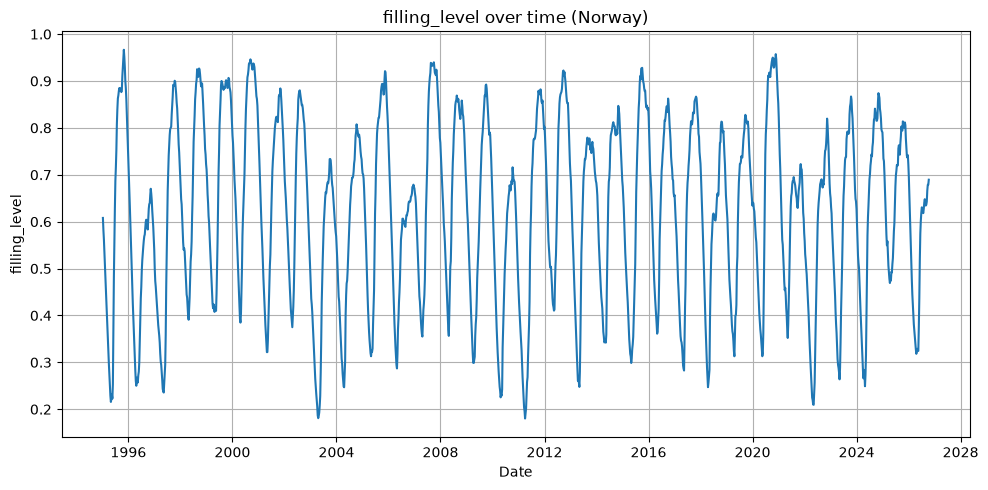

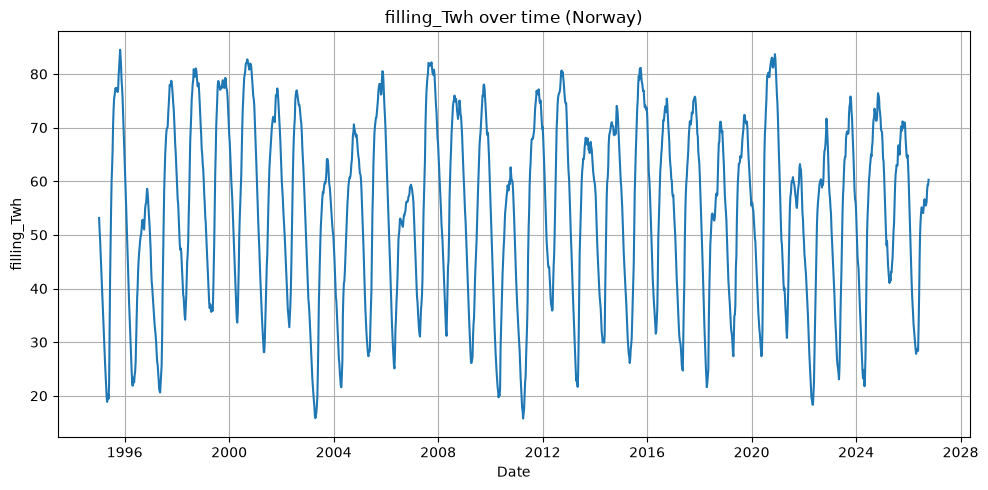

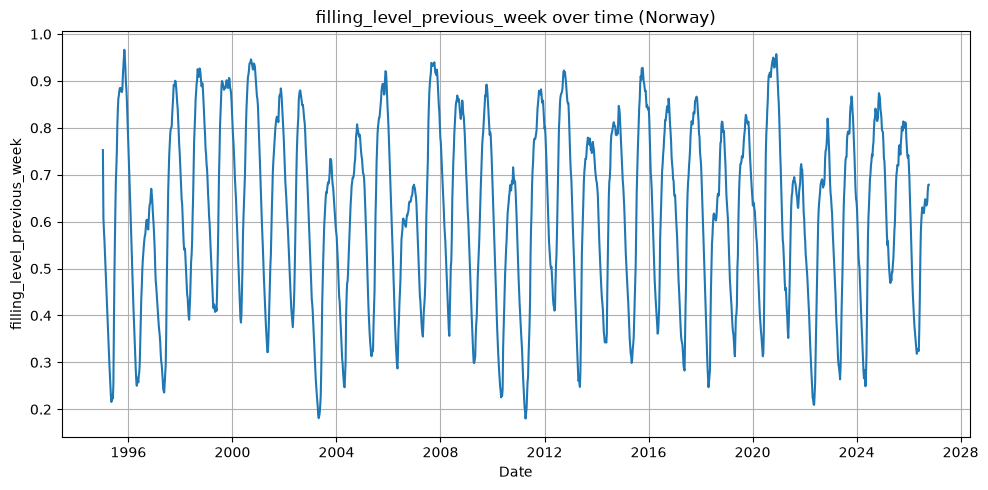

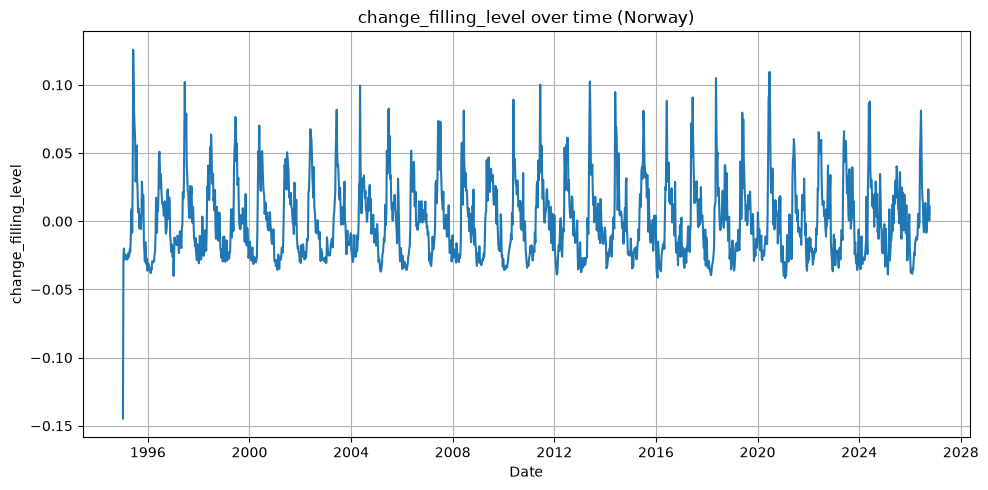

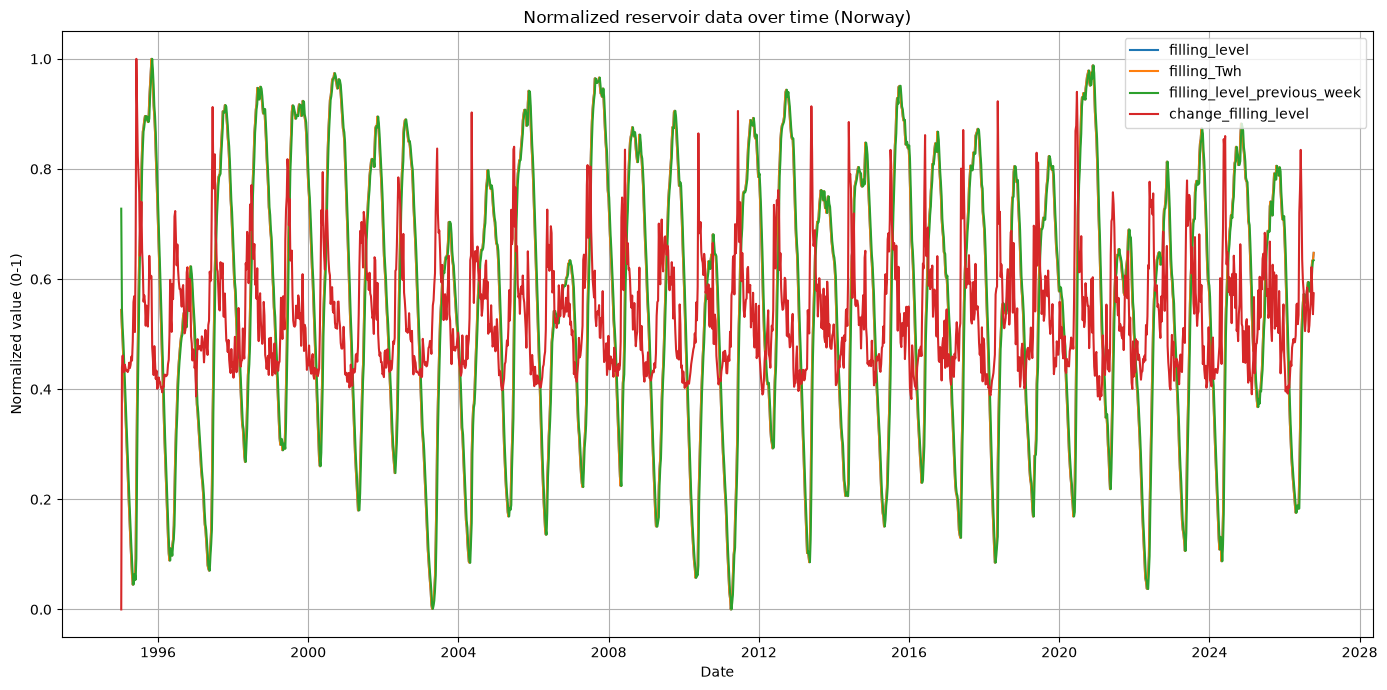

In [ ]:
# Plotting reservoir data for Norway
plot_cols = ['filling_level', 'filling_Twh',
             'filling_level_previous_week', 'change_filling_level']  # same as part 1, no capacity

no_df = select_area(df, "NO", 0)[plot_cols]

# each column separately
for col in no_df.columns:
    plt.figure(figsize=(10, 5))
    plt.plot(no_df.index, no_df[col])
    plt.title(f"{col} over time (Norway)")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# all together, normalized 0-1
norm = ((no_df - no_df.min()) / (no_df.max() - no_df.min())).fillna(0)

plt.figure(figsize=(14, 7))
for col in norm.columns:
    plt.plot(norm.index, norm[col], label=col)
plt.title("Normalized reservoir data over time (Norway)")
plt.xlabel("Date")
plt.ylabel("Normalized value (0-1)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Cassandra

In [ ]:
# Importing cluster from cassandra library and creating a connection to the cassandra databse running on localhost with port 9042
cluster = Cluster(['Localhost'], port = 9042)
session = cluster.connect()

session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

session.set_keyspace('ind320')

In [33]:
# geting the spark session from the spark_setup module
sys.path.append(str(Path.cwd().parent))

from modules.spark_setup import get_spark

### Geting the data from ENTSO-E

In [ ]:
# Fetches physical cross-border flows (A11) from ENTSO-E for Norway's
# international connections, both directions, for the last two years.
# The API allows at most one year per request, so each year is fetched separately.


API_KEY = (Path("../no_sync") / "entsoe_token.txt").read_text().strip()
client = EntsoePandasClient(api_key=API_KEY)

CONNECTIONS = [("NO_1", "SE_3"), ("NO_3", "SE_2"), ("NO_4", "SE_1"), ("NO_4", "SE_2"),
               ("NO_4", "FI"), ("NO_2", "DK_1"), ("NO_2", "NL"), ("NO_2", "DE_LU"), ("NO_2", "GB")]

# Two one-year periods, calculated from today's date
end = pd.Timestamp.now(tz="UTC").normalize()
middle = end - pd.DateOffset(years=1)
start = end - pd.DateOffset(years=2)
PERIODS = [(start, middle), (middle, end)]

# Fetches cross-border flows from ENTSO-E for a given connection and time period.
def fetch_flow(from_area, to_area, start, end):
    """Flow from 'from_area' to 'to_area' as hourly values in UTC without a time zone."""
    s = client.query_crossborder_flows(from_area, to_area, start=start, end=end)
    s = s.tz_convert("UTC").tz_localize(None).resample("h").mean()
    return s.rename("mw").rename_axis("time").reset_index()

# Fetches cross-border flows for all connections and periods, both directions, and combines them into a single DataFrame.
parts = []
for no, foreign in CONNECTIONS:
    for period_start, period_end in PERIODS:
        for from_area, to_area, direction in [(no, foreign, "export"), (foreign, no, "import")]:
            try:
                d = fetch_flow(from_area, to_area, period_start, period_end)
            except Exception as e:
                print(f"No data for {from_area}->{to_area} {period_start.date()}: {type(e).__name__}")
                continue
            d["connection"] = f"{no}-{foreign}"
            d["direction"] = direction
            parts.append(d)

# Combine all parts into a single DataFrame, dropping duplicates based on connection, direction, and time.
df_flow = (pd.concat(parts, ignore_index=True)
             .drop_duplicates(["connection", "direction", "time"]))   

print(df_flow["mw"].isna().sum())                                      
df_flow.groupby(["connection", "direction"]).size()

0


connection  direction
NO_1-SE_3   export       17520
            import       17520
NO_2-DE_LU  export       17520
            import       17520
NO_2-DK_1   export       17520
            import       17520
NO_2-GB     export       17520
            import       17520
NO_2-NL     export       17520
            import       17520
NO_3-SE_2   export       17520
            import       17520
NO_4-FI     export       17520
            import       17520
NO_4-SE_1   export       17520
            import       17520
NO_4-SE_2   export       17520
            import       17520
dtype: int64

### Spark

In [ ]:
# Set up the Spark session
sys.path.append(str(Path.cwd().parent))
from modules.spark_setup import get_spark       

spark = get_spark()
spark.conf.set("spark.sql.session.timeZone", "UTC")   
spark.sql("SHOW NAMESPACES FROM mycatalog").show()    

+---------+
|namespace|
+---------+
|   ind320|
|  test_ks|
+---------+



In [ ]:
# Create a table in Cassandra for cross-border flows, partitioned by connection and direction, with a clustering key on time.
spark.sql("""
    CREATE TABLE IF NOT EXISTS mycatalog.ind320.crossborder_flow (
        connection STRING,
        direction  STRING,
        time       TIMESTAMP,
        mw         DOUBLE
    )
    USING cassandra
    PARTITIONED BY (connection, direction)
    TBLPROPERTIES (clustering_key = 'time.asc')
""")
spark.sql("SHOW TABLES IN mycatalog.ind320").show()

sdf = spark.createDataFrame(df_flow[["connection", "direction", "time", "mw"]])

# Write the Spark DataFrame to the Cassandra table in append mode.
(sdf.write
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="crossborder_flow")
    .mode("append")
    .save())

# Read the data back from Cassandra to verify it was written correctly.
sdf_check = (spark.read.format("org.apache.spark.sql.cassandra")
             .options(keyspace="ind320", table="crossborder_flow")
             .load())

# Check the number of records in the Spark DataFrame and the Cassandra table to ensure they match.
sdf_check.groupBy("connection", "direction").count().orderBy("connection", "direction").show(20)


print(df_flow["time"].min(), df_flow["time"].max())
sdf_check.selectExpr("min(time)", "max(time)").show(truncate=False)

+---------+----------------+-----------+
|namespace|       tableName|isTemporary|
+---------+----------------+-----------+
|   ind320|crossborder_flow|      false|
+---------+----------------+-----------+



C:\Users\simen\AppData\Roaming\Python\Python311\site-packages\pyspark\sql\pandas\conversion.py:351: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  PyArrow >= 4.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
| NO_1-SE_3|   export|17518|
| NO_1-SE_3|   import|17518|
|NO_2-DE_LU|   export|17518|
|NO_2-DE_LU|   import|17518|
| NO_2-DK_1|   export|17518|
| NO_2-DK_1|   import|17518|
|   NO_2-GB|   export|17518|
|   NO_2-GB|   import|17518|
|   NO_2-NL|   export|17518|
|   NO_2-NL|   import|17518|
| NO_3-SE_2|   export|17518|
| NO_3-SE_2|   import|17518|
|   NO_4-FI|   export|17518|
|   NO_4-FI|   import|17518|
| NO_4-SE_1|   export|17518|
| NO_4-SE_1|   import|17518|
| NO_4-SE_2|   export|17518|
| NO_4-SE_2|   import|17518|
+----------+---------+-----+

2024-10-19 00:00:00 2026-10-18 23:00:00
+-------------------+-------------------+
|min(time)          |max(time)          |
+-------------------+-------------------+
|2024-10-18 22:00:00|2026-10-18 21:00:00|
+-------------------+-------------------+



In [ ]:
# Read from Cassandra and pick the relevant columns
sdf_float = (spark.read.format("org.apache.spark.sql.cassandra")
            .options(keyspace="ind320", table="crossborder_flow")
            .load()
            .select("connection", "direction", "time", "mw"))

# Choose a connection. This filter is on the partition key, so it is pushed down to Cassandra
chosen_connection = "NO_2-DE_LU"
sdf_chosen = sdf_float.filter(F.col("connection") == chosen_connection)

# To pandas, converted to Norwegian time before grouping by year and month
pdf = sdf_chosen.toPandas()
pdf["time"] = pdf["time"].dt.tz_localize("UTC").dt.tz_convert("Europe/Oslo")
pdf["year"] = pdf["time"].dt.year
pdf["month"] = pdf["time"].dt.month

# Pie chart: total in and out of Norway for one year
pie_df = pdf[pdf["year"] == 2025].groupby("direction")["mw"].sum()

# Line plot: first month of the year, one line per direction
line_df = pdf[(pdf["year"] == 2025) & (pdf["month"] == 1)]


C:\Users\simen\AppData\Roaming\Python\Python311\site-packages\pyspark\sql\pandas\conversion.py:111: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  PyArrow >= 4.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


[2024 2025 2026]
direction
export    7.787843e+06
import    7.667146e+05
Name: mw, dtype: float64
8554557.43075
<StringArray>
['NO_2-DE_LU']
Length: 1, dtype: str
2024-10-19 00:00:00+02:00
2026-10-18 23:00:00+02:00
year
2025    17518
2026    13966
2024     3552
Name: count, dtype: int64


### Ploting the data for NO_2-DE_LU 

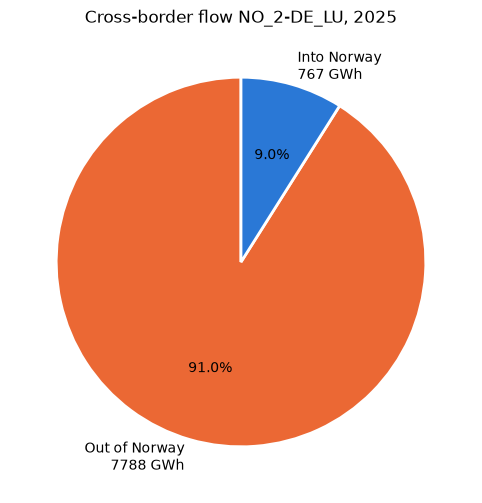

In [ ]:
Year = 2025   # first full calendar year in the data (2024 and 2026 are only partly covered)
Colours = {"import": "#2a78d6", "export": "#eb6834"}   # same colour per direction in both plots
Labels = {"import": "Into Norway", "export": "Out of Norway"}

# Pie chart: total in and out of Norway for one year
# Hourly MW summed over the year = MWh. Divided by 1000 to get GWh
pie_gwh = pie_df / 1000

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    pie_gwh.values,
    labels=[f"{Labels[d]}\n{v:.0f} GWh" for d, v in pie_gwh.items()],
    colors=[Colours[d] for d in pie_gwh.index],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title(f"Cross-border flow {chosen_connection}, {Year}")
plt.show()

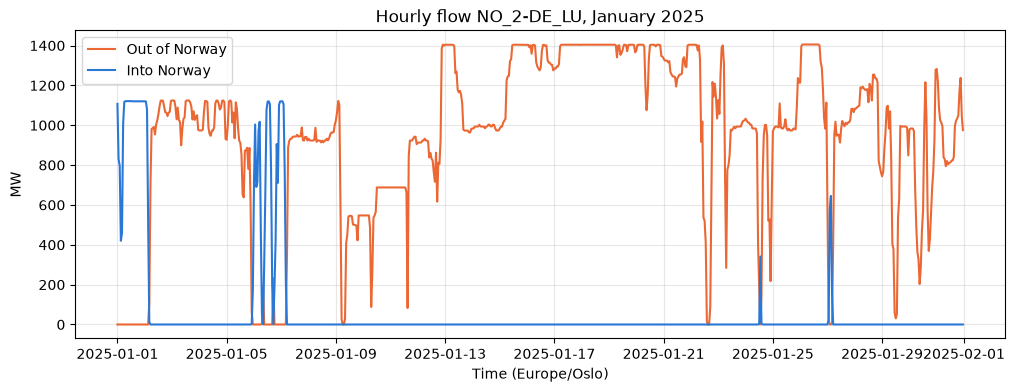

In [ ]:
# Line plot: first month of the year, one line per direction
fig, ax = plt.subplots(figsize=(12, 4))
for retning, gruppe in line_df.groupby("direction"):
    ax.plot(gruppe["time"], gruppe["mw"], label=Labels[retning],
            color=Colours[retning], linewidth=1.5)

ax.set_title(f"Hourly flow {chosen_connection}, January {Year}")
ax.set_xlabel("Time (Europe/Oslo)")
ax.set_ylabel("MW")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

### MongoDB

In [ ]:
# Load the MongoDB URI from the secrets file
with open(Path("../.streamlit/secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)

MONGO_URI = secrets["MONGO_uri"]

mongo_client = MongoClient(MONGO_URI)

# Test the connection to MongoDB by pinging the server
try:
    mongo_client.admin.command('ping')
    print("Pinged your deployment. You are successfully connected to MongoDB!")
except Exception as exception:
    print(exception)

Pinged your deployment. You successfully connected to MongoDB!


In [ ]:
# Testing basic operations on a separate test collection
test = mongo_client["ind320"]["test"]
test.insert_one({"name": "test", "value": 1})                       # Create
print(test.find_one({"name": "test"}))                              # Read
test.update_one({"name": "test"}, {"$set": {"value": 2}})           # Update
print(test.find_one({"name": "test"}))
test.delete_one({"name": "test"})                                   # Delete
mongo_client["ind320"].drop_collection("test");                     # Clean up

{'_id': ObjectId('6ad66ce1572adef6c83a1f7f'), 'name': 'test', 'value': 1}
{'_id': ObjectId('6ad66ce1572adef6c83a1f7f'), 'name': 'test', 'value': 2}


In [ ]:
coll = mongo_client["ind320"]["crossborder_flow"]

# Data extracted from Cassandra with Spark (all connections, hourly values in UTC)
pdf_alle = sdf_flyt.toPandas()

coll.delete_many({})                                    # avoid duplicates if the cell is run again
coll.insert_many(pdf_alle.to_dict("records"))
coll.create_index([("connection", 1), ("time", 1)])     # fast lookups from Streamlit

print(coll.count_documents({}), "number ofdocuments in MongoDB")

C:\Users\simen\AppData\Roaming\Python\Python311\site-packages\pyspark\sql\pandas\conversion.py:111: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  PyArrow >= 4.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


315324 documents in MongoDB
